# Lab Sheet 10 — Capstone Machine Learning Projects
**MCA201P | Semester III | Session 2026–27**

## Projects
1. Loan approval classification with an interactive interface.
2. Symptom-pattern classification with an interactive interface.

> **Safety:** Both training datasets are **synthetic**. These are educational software demonstrations, not loan eligibility decisions or disease diagnosis. Do not collect or use personal data.

Each project compares Logistic Regression and Random Forest on a fixed stratified test split, with preprocessing pipelines and model persistence.

## Step 1 — Generate demonstration datasets

In [1]:
from generate_labs_09_10_data import make_loans, make_symptoms
loan_df=make_loans(); symptoms_df=make_symptoms()
display(loan_df.head()); display(symptoms_df.head())

,income_monthly_inr,loan_amount_inr,credit_history,employment,education,marital_status,loan_term_months,approved
0,78720.11,156569.18,1,Self-employed,Not Graduate,Unmarried,24,1
1,111031.41,1513443.49,1,Salaried,Graduate,Unmarried,36,1
2,133760.85,887712.48,1,Salaried,Not Graduate,Married,36,1
3,172633.42,1739019.50,1,Self-employed,Graduate,Married,36,1
4,150232.56,189525.09,1,Self-employed,Graduate,Married,60,1


,fever,cough,sore_throat,sneezing,itchy_eyes,headache,nausea,body_aches,fatigue,duration_days,condition_label
0,0,1,1,1,1,0,0,0,0,6,Common-cold-like illness
1,0,0,0,0,0,1,1,1,1,3,Migraine-like illness
2,0,1,1,1,0,1,0,0,1,8,Common-cold-like illness
3,1,0,0,1,0,1,1,1,1,9,Influenza-like illness
4,0,1,1,0,0,0,0,0,1,5,Influenza-like illness


## Step 2 — Fit, compare and save both pipelines

In [2]:
from lab_10 import train_loan, train_conditions
loan_results=train_loan()
symptoms_results=train_conditions()
print("Loan weighted F1:", loan_results["best_weighted_f1"])
print("Symptom weighted F1:",symptoms_results["best_weighted_f1"])

loan_approval: best=LogisticRegression, held-out weighted F1=0.7049, example predicted label=1, actual=0


symptom_pattern: best=RandomForest, held-out weighted F1=0.9011, example predicted label=Allergy-like illness, actual=Allergy-like illness
Loan weighted F1: 0.7049309693443254
Symptom weighted F1: 0.9010521343297645


## Step 3 — Explain the held-out classification results

In [3]:
import pandas as pd
for task in ["loan_approval","symptom_pattern"]:
    print("METRICS:",task)
    display(pd.read_csv(f"outputs/lab_10/{task}_model_comparison.csv"))

METRICS: loan_approval


,model,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc
0,LogisticRegression,0.715625,0.703682,0.715625,0.704931,0.703922
1,RandomForest,0.712500,0.698872,0.712500,0.698813,0.730870


METRICS: symptom_pattern


,model,accuracy,precision_weighted,recall_weighted,f1_weighted
0,LogisticRegression,0.9,0.899701,0.9,0.899760
1,RandomForest,0.9,0.902665,0.9,0.901052


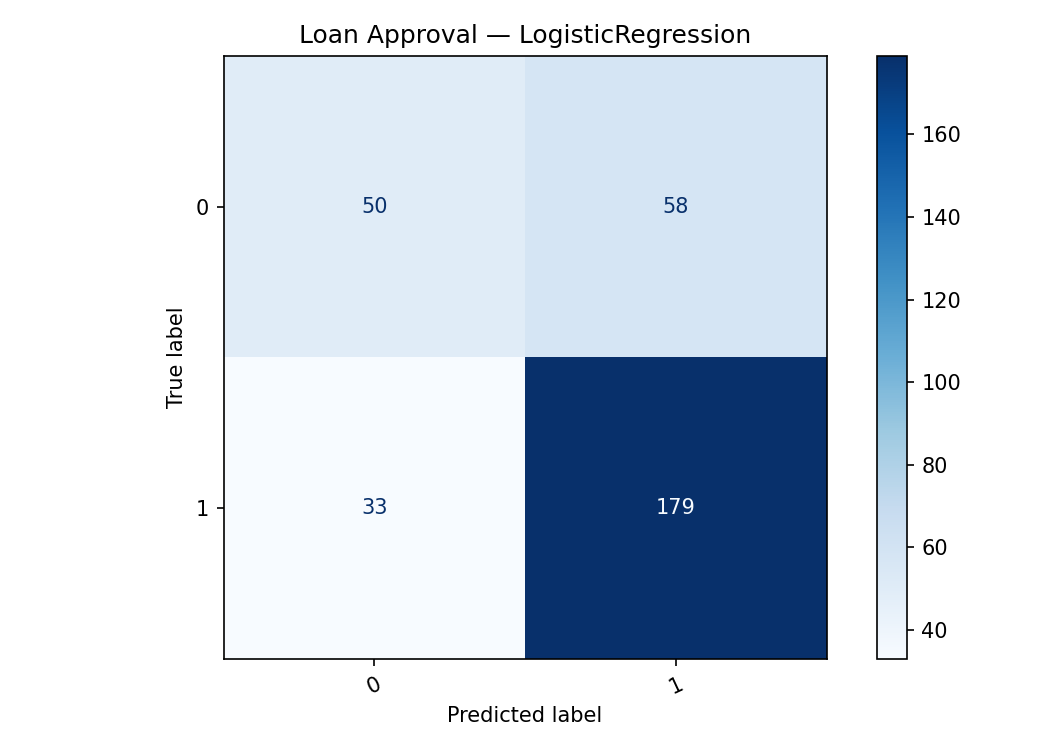

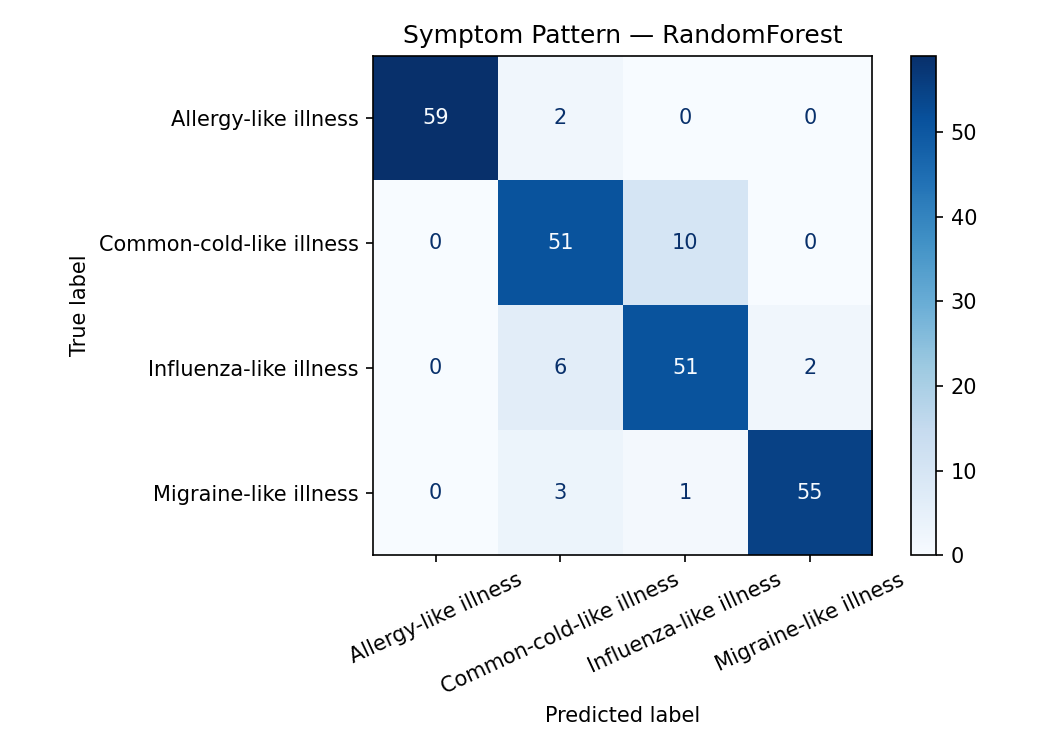

In [4]:
from IPython.display import Image,display
for name in ["loan_approval", "symptom_pattern"]:
    display(Image(filename=f"outputs/lab_10/{name}_confusion_matrix.png"))

## Step 4 — Use a trained pipeline for demonstration inference

In [5]:
import joblib
loan_pipeline=joblib.load("outputs/lab_10/loan_approval_pipeline.joblib")
example=loan_df.drop(columns=["approved"]).iloc[[0]]
print("Demonstration prediction:",loan_pipeline.predict(example)[0])

Demonstration prediction: 1


## Step 5 — Run the optional prediction interface
In a local terminal, run:
```powershell
pip install streamlit
streamlit run lab_10_app.py
```
Choose **Loan Approval Prediction** or **Symptom-Pattern Classification**. Models must be trained first.

## Architecture and control flow
```text
Synthetic CSV → validation → stratified train/test split
      → preprocessing + model pipelines → evaluation and selection
      → saved joblib model → Streamlit UI → demonstration output
```

## Conclusion
The models demonstrate preprocessing, model comparison, evaluation, persistence and a UI. Results depend on synthetic data-generating rules and provide no evidence of real-world utility or medical safety.